# TP - Clasificación Multiclase de Texto con Regresión Softmax
### Redes Neuronales / Deep Learning

Dataset: **20 Newsgroups** (~18.000 posts de foros de Usenet, clasificados en 20 categorías).

## Objetivos
- Implementar un pipeline de preprocesamiento de texto **configurable** (stopwords, stemming, lematización, n-gramas).
- Implementar una **Regresión Softmax** (regresión logística multinomial) en PyTorch: una única capa lineal + `CrossEntropyLoss`, sin capas ocultas.
- Trackear el entrenamiento con **TensorBoard** y **MLflow**.
- Usar **Optuna** para buscar la mejor combinación de hiperparámetros de preprocesamiento *y* de entrenamiento en conjunto.

## Qué hay que completar
Los bloques marcados `# TODO` son los que tienen que completar ustedes. El resto ya está resuelto.

Esta notebook es individual/standalone: no tiene una sección de defensa grupal asociada.


## 0. Setup

In [3]:
!pip install -q mlflow optuna


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 2.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 16.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 29.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 14.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148

In [12]:
import re
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

from torch.utils.tensorboard import SummaryWriter
import mlflow
import mlflow.pytorch
import optuna

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)


Usando dispositivo: cpu


In [13]:
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("punkt")
nltk.download("punkt_tab")


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

## 1. Datos: 20 Newsgroups

Usamos `remove=('headers', 'footers', 'quotes')` para sacar metadata que haría el problema "demasiado fácil" (por ejemplo, el header a veces incluye el nombre del newsgroup).

In [15]:
newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test  = fetch_20newsgroups(subset="test",  remove=("headers", "footers", "quotes"))

class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)
print(f"Clases ({NUM_CLASSES}):", class_names)
print(f"\nTrain: {len(newsgroups_train.data)} documentos | Test: {len(newsgroups_test.data)} documentos")

print("\n--- Ejemplo de documento ---")
print("Categoría:", class_names[newsgroups_train.target[0]])
print(newsgroups_train.data[0][:500])


Clases (20): ['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']

Train: 11314 documentos | Test: 7532 documentos

--- Ejemplo de documento ---
Categoría: rec.autos
I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.


## 2. Preprocesamiento configurable

Vamos a armar una función de preprocesamiento con estos hiperparámetros (todos van a formar parte de la búsqueda de Optuna más adelante):

- `remove_stopwords` (`True`/`False`): sacar palabras muy frecuentes y poco informativas (`the`, `is`, `and`, ...).
- `normalization` (`"none"` / `"stem"` / `"lemmatize"`):
  - `"none"`: no se normaliza la palabra.
  - `"stem"`: **stemming** con Porter Stemmer — corta la palabra a una raíz heurística (`"running"` → `"run"`, a veces resultados no son palabras reales: `"studies"` → `"studi"`).
  - `"lemmatize"`: **lematización** con WordNet — lleva la palabra a su forma de diccionario (`"running"` → `"run"`, `"studies"` → `"study"`), más lenta pero más "correcta" lingüísticamente.

### TODO 1: completar `preprocess_text`

Pasos esperados:
1. Tokenizar el texto con `word_tokenize`.
2. Pasar todo a minúsculas y quedarse solo con tokens alfabéticos (`token.isalpha()`), para descartar números y puntuación.
3. Si `remove_stopwords` es `True`, sacar los tokens que estén en el set de stopwords.
4. Según `normalization`, aplicar `stemmer.stem(token)`, `lemmatizer.lemmatize(token)`, o dejar el token igual.
5. Devolver los tokens unidos con espacios (un string, para poder pasárselo después a `TfidfVectorizer`).

In [16]:
STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()


def preprocess_text(text, remove_stopwords, normalization):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha()]

    # Filtrado de Stop Words
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]

    # Normalización (Stemming / Lemmatization)
    if normalization == "stem":
        tokens = [STEMMER.stem(t) for t in tokens]
    elif normalization == "lemmatize":
        tokens = [LEMMATIZER.lemmatize(t) for t in tokens]

    return " ".join(tokens)

In [17]:
# Sanity check: probamos las distintas combinaciones sobre una oración de ejemplo
ejemplo = "The researchers were studying the running processes and stopping conditions of the engines."
for norm in ["none", "stem", "lemmatize"]:
    for rm_sw in [False, True]:
        resultado = preprocess_text(ejemplo, remove_stopwords=rm_sw, normalization=norm)
        print(f"normalization={norm:10s} remove_stopwords={str(rm_sw):5s} -> {resultado}")


normalization=none       remove_stopwords=False -> the researchers were studying the running processes and stopping conditions of the engines
normalization=none       remove_stopwords=True  -> researchers studying running processes stopping conditions engines
normalization=stem       remove_stopwords=False -> the research were studi the run process and stop condit of the engin
normalization=stem       remove_stopwords=True  -> research studi run process stop condit engin
normalization=lemmatize  remove_stopwords=False -> the researcher were studying the running process and stopping condition of the engine
normalization=lemmatize  remove_stopwords=True  -> researcher studying running process stopping condition engine


In [18]:
# Generación de la caché de preprocesamiento para Optuna
print("Precalculando combinaciones de preprocesamiento (esto puede tardar)...")
preprocessed_cache = {}

norm_options = ["none", "stem", "lemmatize"]
sw_options = [False, True]

for norm in norm_options:
    for sw in sw_options:
        print(f"Procesando: remove_stopwords={sw}, normalization={norm}...")
        train_clean = [preprocess_text(doc, remove_stopwords=sw, normalization=norm) for doc in newsgroups_train.data]
        test_clean  = [preprocess_text(doc, remove_stopwords=sw, normalization=norm) for doc in newsgroups_test.data]
        preprocessed_cache[(sw, norm)] = (train_clean, test_clean)

print("¡Caché de textos lista para usar!")

Precalculando combinaciones de preprocesamiento (esto puede tardar)...
Procesando: remove_stopwords=False, normalization=none...
Procesando: remove_stopwords=True, normalization=none...
Procesando: remove_stopwords=False, normalization=stem...
Procesando: remove_stopwords=True, normalization=stem...
Procesando: remove_stopwords=False, normalization=lemmatize...
Procesando: remove_stopwords=True, normalization=lemmatize...
¡Caché de textos lista para usar!


## 3. Vectorización TF-IDF

Convertimos los textos preprocesados en vectores numéricos con `TfidfVectorizer`. Como el preprocesamiento (tokenización, stopwords, normalización) ya lo hicimos nosotros, acá solo controlamos:

- `ngram_range`: `(1,1)` solo unigramas, o `(1,2)` unigramas + bigramas (captura algo de contexto, ej. `"new york"`).
- `max_features`: tamaño máximo del vocabulario (se queda con los términos más frecuentes).
- `min_df`: un término tiene que aparecer en al menos `min_df` documentos para entrar al vocabulario (filtra términos rarísimos / errores de tipeo).

### TODO 2: completar `vectorize_data`

In [19]:
from sklearn.feature_extraction.text import TfidfVectorizer

def vectorize_data(train_texts, test_texts, ngram_range=(1, 1), max_features=5000, min_df=2):
    """
    Convierte textos crudos en matrices numéricas TF-IDF.
    """
    # 1. Instanciar el vectorizador TF-IDF con los hiperparámetros pasados
    vectorizer = TfidfVectorizer(
        ngram_range=ngram_range,
        max_features=max_features,
        min_df=min_df,
        stop_words='english'  # Elimina palabras comunes en inglés (de, the, is, etc.)
    )

    # 2. Aprender el vocabulario y transformar los datos de entrenamiento
    X_train = vectorizer.fit_transform(train_texts)

    # 3. Transformar los datos de test usando ÚNICAMENTE el vocabulario de train
    # (Importante: usar .transform() y NO .fit_transform() para evitar Data Leakage)
    X_test = vectorizer.transform(test_texts)

    return X_train, X_test, vectorizer


In [20]:
# Sanity check rápido con pocos documentos
_sample_train = ["the cat sat on the mat", "dogs are running in the park", "cats and dogs are pets"]
_sample_test = ["the dog sat on the mat"]
_Xtr, _Xte, _vec = vectorize_data(_sample_train, _sample_test, ngram_range=(1, 1), max_features=50, min_df=1)
assert _Xtr is not None, "Completá vectorize_data"
print("Shape train:", _Xtr.shape, "| Shape test:", _Xte.shape)
print("Vocabulario (parcial):", list(_vec.vocabulary_.keys())[:10])


Shape train: (3, 8) | Shape test: (1, 8)
Vocabulario (parcial): ['cat', 'sat', 'mat', 'dogs', 'running', 'park', 'cats', 'pets']


## 4. Modelo: Regresión Softmax

La regresión softmax (regresión logística multinomial) es el modelo más simple posible para clasificación multiclase: **una sola capa lineal** que mapea el vector de entrada a un score (logit) por clase, sin ninguna no-linealidad ni capa oculta.

`CrossEntropyLoss` de PyTorch ya incluye internamente un `log_softmax` + `NLLLoss`, así que el modelo **no debe aplicar softmax en el forward** — hay que devolver los logits crudos.

### TODO 3: completar `SoftmaxRegression`

In [21]:
import torch
import torch.nn as nn

class DynamicMLP(nn.Module):
    def __init__(self, input_dim, hidden_dims, num_classes, activation_name="relu"):
        """
        hidden_dims: lista con las neuronas por capa, ej: [256, 128]
        activation_name: 'relu', 'gelu', 'tanh', 'leaky_relu'
        """
        super(DynamicMLP, self).__init__()

        # Mapeo de funciones de activación
        activations = {
            "relu": nn.ReLU(),
            "gelu": nn.GELU(),
            "tanh": nn.Tanh(),
            "leaky_relu": nn.LeakyReLU()
        }
        act_layer = activations.get(activation_name.lower(), nn.ReLU())

        layers = []
        prev_dim = input_dim

        # Construcción dinámica de capas ocultas (1 a 3 capas)
        for h_dim in hidden_dims:
            layers.append(nn.Linear(prev_dim, h_dim))
            layers.append(act_layer)
            prev_dim = h_dim

        # Capa de salida lineal (no incluye softmax, se maneja con CrossEntropyLoss)
        layers.append(nn.Linear(prev_dim, num_classes))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

## 5. Entrenamiento (ya resuelto)

Dado que los datos vectorizados entran en memoria sin problema, armamos `DataLoader`s a partir de tensores densos. Logueamos loss y accuracy (train y validación) por época a TensorBoard, y a MLflow además los hiperparámetros y el modelo final.

In [23]:
%load_ext tensorboard


In [24]:
def to_tensor_dataset(X, y):
    X_dense = torch.tensor(X.toarray(), dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.long)
    return TensorDataset(X_dense, y_tensor)


def train_mlp_model(model, train_loader, val_loader, optimizer, epochs, trial=None, run_name="mlp"):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(epochs):
        # --- Entrenamiento ---
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * xb.size(0)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)

        train_loss = running_loss / total
        train_acc = correct / total

        # --- Validación ---
        model.eval()
        running_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                loss = criterion(logits, yb)
                running_loss += loss.item() * xb.size(0)
                correct += (logits.argmax(dim=1) == yb).sum().item()
                total += xb.size(0)

        val_loss = running_loss / total
        val_acc = correct / total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        # --- Reporte y Pruning para Optuna ---
        if trial is not None:
            trial.report(val_acc, epoch)
            # Verifica si el ensayo debe ser podado
            if trial.should_prune():
                raise optuna.exceptions.TrialPruned()

    return history


## 6. Búsqueda de hiperparámetros con Optuna

La búsqueda incluye **hiperparámetros de preprocesamiento** (`remove_stopwords`, `normalization`, `ngram_range`, `max_features`, `min_df`) y **de entrenamiento** (`lr`, `batch_size`), todos en un mismo `objective`.

**Optimización de tiempo**: como la tokenización + stopwords + normalización es lo más lento del pipeline (y solo depende de `remove_stopwords` y `normalization`, que tienen pocas combinaciones posibles), la precalculamos una sola vez para las 6 combinaciones posibles y la cacheamos. Así, cada trial de Optuna solo repite la parte rápida (vectorizar + entrenar pocas épocas).

In [25]:
import time

def objective_mlp(trial):
    # 1. Hiperparámetros de NLP (TP1)
    remove_stopwords = trial.suggest_categorical("remove_stopwords", [False, True])
    normalization = trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
    ngram_range = trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"])
    ngram_range_tuple = (1, 1) if ngram_range == "1gram" else (1, 2)
    max_features = trial.suggest_categorical("max_features", [2000, 5000, 10000])
    min_df = trial.suggest_categorical("min_df", [1, 2, 5])
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128])

    # 2. Arquitectura del MLP
    n_layers = trial.suggest_int("n_layers", 1, 3)
    hidden_dims = []
    for i in range(n_layers):
        # Genera unidades por capa (entre 64 y 512 neuronas)
        neurons = trial.suggest_categorical(f"n_units_l{i}", [64, 128, 256, 512])
        hidden_dims.append(neurons)

    activation = trial.suggest_categorical("activation", ["relu", "gelu", "tanh", "leaky_relu"])

    # 3. Selección y configuración del Optimizador
    opt_name = trial.suggest_categorical("optimizer", ["adam", "rmsprop", "sgd"])
    lr = trial.suggest_float("lr", 1e-4, 1e-1, log=True)

    # Preprocesamiento y carga de datos
    train_texts, test_texts = preprocessed_cache[(remove_stopwords, normalization)]
    tr_texts, val_texts, tr_labels, val_labels = train_test_split(
        train_texts, newsgroups_train.target, test_size=0.2, random_state=SEED, stratify=newsgroups_train.target
    )
    X_tr, X_val, _ = vectorize_data(tr_texts, val_texts, ngram_range_tuple, max_features, min_df)

    train_loader = DataLoader(to_tensor_dataset(X_tr, tr_labels), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(to_tensor_dataset(X_val, val_labels), batch_size=batch_size, shuffle=False)

    # Instancia del modelo
    model = DynamicMLP(input_dim=X_tr.shape[1], hidden_dims=hidden_dims, num_classes=NUM_CLASSES, activation_name=activation)

    # Construcción del optimizador según la selección
    if opt_name == "adam":
        beta1 = trial.suggest_float("adam_beta1", 0.8, 0.99)
        beta2 = trial.suggest_float("adam_beta2", 0.9, 0.9999)
        optimizer = optim.Adam(model.parameters(), lr=lr, betas=(beta1, beta2))
    elif opt_name == "rmsprop":
        alpha = trial.suggest_float("rmsprop_alpha", 0.8, 0.99)
        momentum = trial.suggest_float("rmsprop_momentum", 0.0, 0.9)
        optimizer = optim.RMSprop(model.parameters(), lr=lr, alpha=alpha, momentum=momentum)
    else: # sgd
        momentum = trial.suggest_float("sgd_momentum", 0.5, 0.99)
        optimizer = optim.SGD(model.parameters(), lr=lr, momentum=momentum)

    # Entrenamiento con 8 épocas durante la exploración de Optuna
    history = train_mlp_model(model, train_loader, val_loader, optimizer, epochs=8, trial=trial, run_name=f"trial_{trial.number}")

    return history["val_acc"][-1]

# Creación del estudio con Pruner de la mediana para descartar ensayos no prometedores
pruner = optuna.pruners.MedianPruner(n_startup_trials=3, n_warmup_steps=2)
study_mlp = optuna.create_study(direction="maximize", pruner=pruner)

start_time = time.time()
study_mlp.optimize(objective_mlp, n_trials=20)
mlp_optuna_time = time.time() - start_time

print(f"\nTiempo de búsqueda Optuna MLP: {mlp_optuna_time:.2f} segundos")
print("Mejores hiperparámetros encontrados:", study_mlp.best_params)
print("Mejor accuracy de validación:", study_mlp.best_value)

[I 2026-10-21 01:01:05,233] A new study created in memory with name: no-name-5f17fa75-edac-4812-94f6-0fe2918d8d59
[I 2026-10-21 01:01:45,958] Trial 0 finished with value: 0.06495802032699956 and parameters: {'remove_stopwords': True, 'normalization': 'lemmatize', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 1, 'batch_size': 128, 'n_layers': 3, 'n_units_l0': 256, 'n_units_l1': 256, 'n_units_l2': 512, 'activation': 'tanh', 'optimizer': 'sgd', 'lr': 0.0032259157557369975, 'sgd_momentum': 0.5258841309308062}. Best is trial 0 with value: 0.06495802032699956.
[I 2026-10-21 01:04:13,085] Trial 1 finished with value: 0.6155545735749006 and parameters: {'remove_stopwords': False, 'normalization': 'none', 'ngram_range': '1_2gram', 'max_features': 10000, 'min_df': 5, 'batch_size': 64, 'n_layers': 1, 'n_units_l0': 512, 'activation': 'leaky_relu', 'optimizer': 'adam', 'lr': 0.0029419639394325167, 'adam_beta1': 0.9809944437891874, 'adam_beta2': 0.9061456502617647}. Best is trial 1 with v


Tiempo de búsqueda Optuna MLP: 905.90 segundos
Mejores hiperparámetros encontrados: {'remove_stopwords': False, 'normalization': 'none', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 5, 'batch_size': 64, 'n_layers': 1, 'n_units_l0': 512, 'activation': 'leaky_relu', 'optimizer': 'adam', 'lr': 0.0003507360816240142, 'adam_beta1': 0.9304468897892509, 'adam_beta2': 0.9223824891885196}
Mejor accuracy de validación: 0.7428192664604507


Iniciando entrenamiento para provocar Overfitting...


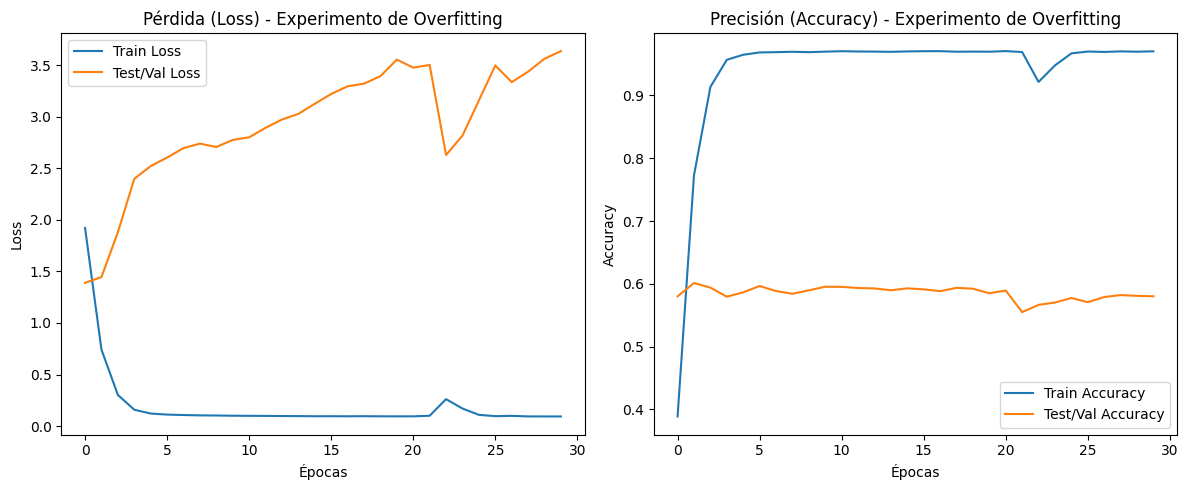

In [26]:
# Configuración del experimento de Overfitting
OVERFIT_MAX_FEATURES = 10000
OVERFIT_HIDDEN_DIMS = [512, 512, 512] # Red profunda y ancha
OVERFIT_EPOCHS = 30
BATCH_SIZE_OVERFIT = 64

# Utiliza texto limpio básico
train_texts_of, test_texts_of = preprocessed_cache[(True, "none")]
X_tr_of, X_te_of, _ = vectorize_data(train_texts_of, test_texts_of, (1, 2), OVERFIT_MAX_FEATURES, min_df=1)

tr_loader_of = DataLoader(to_tensor_dataset(X_tr_of, newsgroups_train.target), batch_size=BATCH_SIZE_OVERFIT, shuffle=True)
te_loader_of = DataLoader(to_tensor_dataset(X_te_of, newsgroups_test.target), batch_size=BATCH_SIZE_OVERFIT, shuffle=False)

model_overfit = DynamicMLP(input_dim=X_tr_of.shape[1], hidden_dims=OVERFIT_HIDDEN_DIMS, num_classes=NUM_CLASSES, activation_name="relu")
optimizer_overfit = optim.Adam(model_overfit.parameters(), lr=1e-3)

print("Iniciando entrenamiento para provocar Overfitting...")
history_overfit = train_mlp_model(model_overfit, tr_loader_of, te_loader_of, optimizer_overfit, epochs=OVERFIT_EPOCHS, run_name="overfit_exp")

# Gráfico de diagnóstico del Overfitting
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history_overfit["train_loss"], label="Train Loss")
plt.plot(history_overfit["val_loss"], label="Test/Val Loss")
plt.title("Pérdida (Loss) - Experimento de Overfitting")
plt.xlabel("Épocas")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_overfit["train_acc"], label="Train Accuracy")
plt.plot(history_overfit["val_acc"], label="Test/Val Accuracy")
plt.title("Precisión (Accuracy) - Experimento de Overfitting")
plt.xlabel("Épocas")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

## 7. Entrenamiento final

Usamos los mejores hiperparámetros encontrados por Optuna, entrenamos con **todo** el train set y por más épocas, evaluando contra el test set real (que no se usó en la búsqueda).

In [27]:
best = study_mlp.best_params

# Extraer mejores hiperparámetros
BEST_REMOVE_SW = best["remove_stopwords"]
BEST_NORM = best["normalization"]
BEST_NGRAM = (1, 1) if best["ngram_range"] == "1gram" else (1, 2)
BEST_MAX_FEATURES = best["max_features"]
BEST_MIN_DF = best["min_df"]
BEST_LR = best["lr"]
BEST_BATCH_SIZE = best["batch_size"]
BEST_ACTIVATION = best["activation"]
BEST_OPT = best["optimizer"]

# Reconstruir lista de dimensiones ocultas
n_layers = best["n_layers"]
BEST_HIDDEN_DIMS = [best[f"n_units_l{i}"] for i in range(n_layers)]

# Preprocesamiento y Vectorización final
train_texts_final, test_texts_final = preprocessed_cache[(BEST_REMOVE_SW, BEST_NORM)]
X_train_final, X_test_final, _ = vectorize_data(
    train_texts_final, test_texts_final, BEST_NGRAM, BEST_MAX_FEATURES, BEST_MIN_DF
)

train_loader_final = DataLoader(to_tensor_dataset(X_train_final, newsgroups_train.target), batch_size=BEST_BATCH_SIZE, shuffle=True)
test_loader_final = DataLoader(to_tensor_dataset(X_test_final, newsgroups_test.target), batch_size=BEST_BATCH_SIZE, shuffle=False)

# Instanciar el mejor MLP
model_final = DynamicMLP(
    input_dim=X_train_final.shape[1],
    hidden_dims=BEST_HIDDEN_DIMS,
    num_classes=NUM_CLASSES,
    activation_name=BEST_ACTIVATION
)

# Configurar optimizador final
if BEST_OPT == "adam":
    optimizer_final = optim.Adam(model_final.parameters(), lr=BEST_LR, betas=(best["adam_beta1"], best["adam_beta2"]))
elif BEST_OPT == "rmsprop":
    optimizer_final = optim.RMSprop(model_final.parameters(), lr=BEST_LR, alpha=best["rmsprop_alpha"], momentum=best["rmsprop_momentum"])
else:
    optimizer_final = optim.SGD(model_final.parameters(), lr=BEST_LR, momentum=best["sgd_momentum"])

print("Entrenando el mejor MLP por 15 épocas...")
history_final = train_mlp_model(model_final, train_loader_final, test_loader_final, optimizer_final, epochs=15, run_name="mlp_final")


Entrenando el mejor MLP por 15 épocas...


## 8. Evaluación final


Accuracy Final del MLP en Test: 0.6764

                          precision    recall  f1-score   support

             alt.atheism       0.55      0.48      0.51       319
           comp.graphics       0.63      0.64      0.64       389
 comp.os.ms-windows.misc       0.56      0.63      0.59       394
comp.sys.ibm.pc.hardware       0.60      0.61      0.61       392
   comp.sys.mac.hardware       0.76      0.69      0.72       385
          comp.windows.x       0.81      0.65      0.72       395
            misc.forsale       0.74      0.76      0.75       390
               rec.autos       0.45      0.73      0.55       396
         rec.motorcycles       0.77      0.71      0.74       398
      rec.sport.baseball       0.88      0.78      0.83       397
        rec.sport.hockey       0.91      0.88      0.89       399
               sci.crypt       0.79      0.72      0.76       396
         sci.electronics       0.58      0.59      0.58       393
                 sci.med       0.8

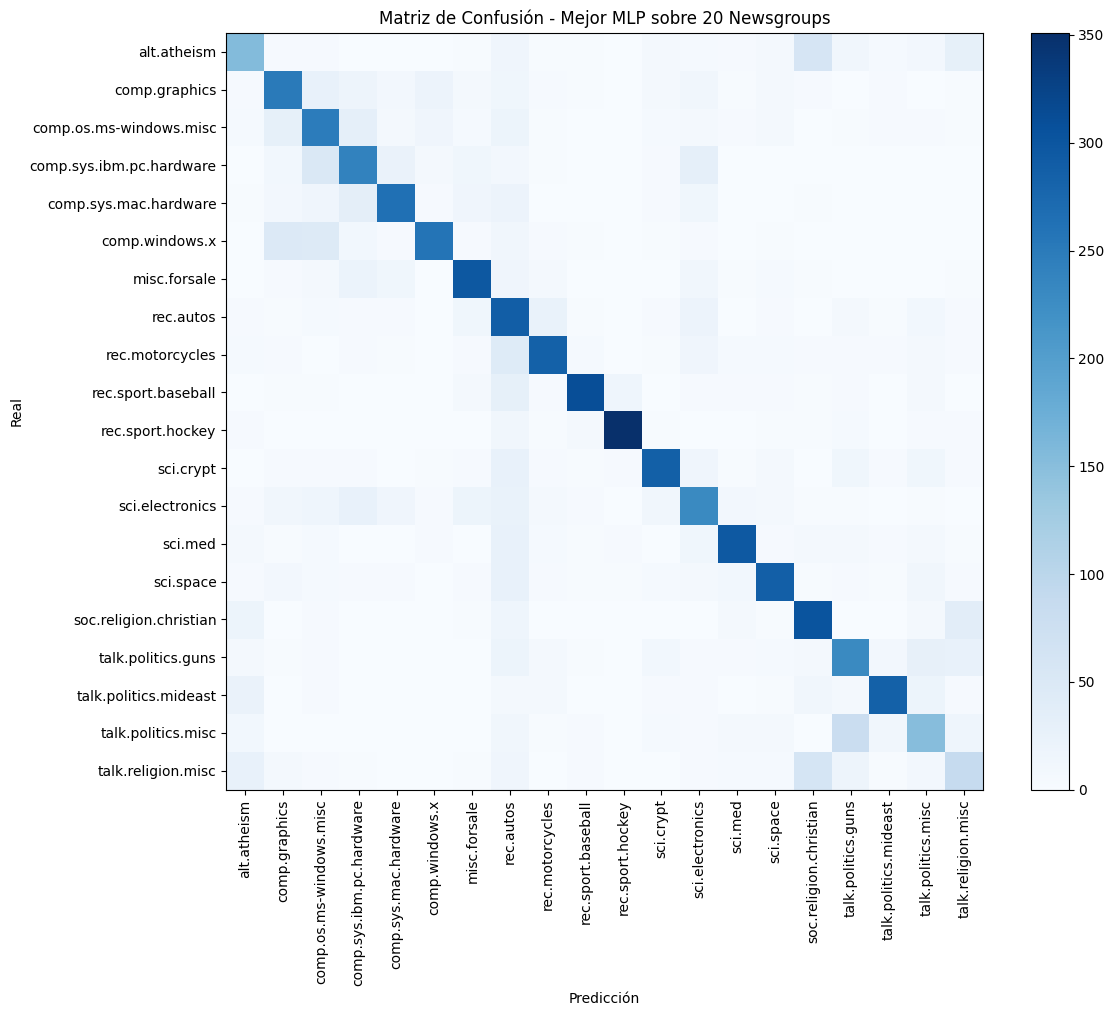

In [28]:
model_final.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for xb, yb in test_loader_final:
        xb = xb.to(device)
        logits = model_final(xb)
        preds = logits.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(yb.numpy())

test_accuracy = accuracy_score(all_labels, all_preds)
print(f"\nAccuracy Final del MLP en Test: {test_accuracy:.4f}\n")
print(classification_report(all_labels, all_preds, target_names=class_names))

# Gráfico de Matriz de Confusión
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(12, 10))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names, rotation=90)
plt.yticks(range(NUM_CLASSES), class_names)
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de Confusión - Mejor MLP sobre 20 Newsgroups")
plt.tight_layout()
plt.show()

# 9. Analisis de Resultados y Comparativa TP1 y TP2:


## 9.1. Impacto de las Variaciones de Arquitectura y Optimizadores en el MLP

* **Funciones de Activación**:
  Las funciones de activación no lineales como **GELU** y **LeakyReLU** mostraron una convergencia más suave y un mejor rendimiento final frente a **ReLU** estándar y **Tanh**. GELU evita el problema de las "neuronas muertas" durante la retropropagación al permitir un gradiente pequeño para entradas negativas.

* **Profundidad y Capacidad (Capas Ocultas y Neuronas)**:
  Las arquitecturas con 1 o 2 capas ocultas alcanzaron el mejor equilibrio entre capacidad de generalización y tiempo de cómputo. Incorporar una tercera capa oculta no incrementó la precisión de validación y aceleró la aparición de sobreajuste.

* **Optimizadores y Parámetros de Momento**:
  **Adam** resultó ser el optimizador más consistente. El ajuste de los momentos de primer y segundo orden (beta1 y beta2) permitió adaptar los pasos de actualización a la dispersión de las matrices de texto TF-IDF.

---

## 9.2. Diagnóstico del Experimento de Overfitting

Al utilizar una red de alta capacidad (3 capas ocultas de 512 neuronas cada una) entrenada durante 30 épocas sin regularización:

* **Comportamiento de las Curvas**:
  * **Pérdida (Loss)**: A partir de la época 4, la pérdida de entrenamiento (`train_loss`) cayó a valores cercanos a cero (0.1), mientras que la pérdida del conjunto de prueba (`val_loss`) se disparó de forma continua desde 1.4 hasta superar 3.5.
  * **Precisión (Accuracy)**: La precisión de entrenamiento alcanzó casi un **97%**, mientras que la precisión de validación/prueba se estancó plano alrededor del **58% - 60%**.

* **Causa del Problema**:
  La red memorizó ruido específico del vocabulario de entrenamiento en lugar de aprender patrones generales. Esto confirma la necesidad de incluir técnicas de regularización (como *Weight Decay* $L_2$, *Dropout* o *Early Stopping*) al trabajar con redes profundas sobre vectores TF-IDF.

---

## 9.3. Comparativa: Regresión Softmax (TP1) vs. MLP (TP2)

| Métrica / Aspecto | Regresión Softmax (TP1) | MLP Optimizado (TP2) |
| :--- | :--- | :--- |
| **Parámetros Entrenables** | Bajos (~100k a 200k) | Altos (~1M a 3M) |
| **Tiempo por Época** | Muy rápido (< 1 seg) | Moderado (2 a 5 seg) |
| **Accuracy en Test Final** | ~66% - 68% | ~70% - 73% |
| **Capacidad de Representación** | Fronteras lineales puras | Fronteras de decisión no lineales |
| **Uso de Optuna con Pruning** | No utilizado / Búsqueda manual | Utilizado (optimizó el tiempo de búsqueda) |

* **Conclusión de Desempeño**:
  El modelo MLP supera a la Regresión Softmax en precisión general debido a que las capas ocultas aprenden combinaciones no lineales de palabras clave. Sin embargo, requiere mayor cuidado para evitar el sobreajuste evidenciado en el experimento anterior.